# Programme-end Purchase Prediction

In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
BASE = Path.cwd()
if not (BASE / "evidence").exists():
    BASE = BASE / "notebooks" 
assert (BASE / "evidence").is_dir(), "Open from the project root or notebooks."
EVIDENCE = BASE / "evidence"
def read_json(name):
    return json.loads((EVIDENCE / name).read_text(encoding="utf-8-sig"))
pd.set_option("display.max_colwidth", 90)
plt.rcParams.update({"figure.figsize": (10, 4.5), "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 11})


## Question

At the final recorded paid visit, will the customer have another distinct programme purchase recorded in Sales within 90 days?

One row is one programme-end decision. A purchase already recorded by that date is excluded. Linked upsells remain one programme. Warranty visits are not purchases. Calendar dates describe recorded visits, not verified treatment completion.

In [2]:
E = EVIDENCE / "programme_end_purchase"
result = json.loads((E / "results.json").read_text())
scope = json.loads((E / "feasibility.json").read_text())
validation = pd.read_json(E / "validation_results.json")
display(pd.DataFrame([{"Selected model": result["selected"], "Inputs": result["input_count"],
                       "Encoded columns": result["encoded_columns"], "Deployed": result["deployed"]}]))


Selected model,Inputs,Encoded columns,Deployed
Balanced logistic regression C=0.1 / core_and_weather,17,33,False


## Result

The selected model flagged two cases: one actual buyer and one false warning. It missed 15 of the 16 buyers. Precision is 50%, recall is 6.25%, and accuracy is 95.38% — the same accuracy as always predicting no additional purchase. It is not suitable for deployment.

Only four validation buyers and sixteen test buyers were available. These historical periods were examined in earlier studies; this is a new target experiment, not an independent future test.

## Labelled data

Label 1: another programme starts after the final recorded visit and within the next 90 days. Label 0: no such purchase appears during a complete 90-day observation period. Immature windows and ambiguous identities/final visits are excluded, not labelled zero.

The private working dataset is `outputs/model_validation/20261030_programme_end_purchase/labelled_programmes_private.csv`. Customer and programme keys are used only to join or separate records, never as predictors. The label builder is `scripts/research_programme_end_purchase.py:build`.

In [3]:
display(pd.DataFrame([{"Data check": k.replace("_", " "), "Programme rows": v}
                      for k,v in scope["audit"].items()]))


Data check,Programme rows
programmes seen,2537
no unique customer and dated sale,140
missing or ambiguous final visit,493
outcome not mature,168
another programme already recorded,10
unknown paid session count,10
programme not fully purchased at anchor,5
eligible programme windows,1711


## Training, validation and test

Dates were chosen from the 60th and 80th percentiles of eligible anchor dates, without selecting a split by model score. Ninety-day maturity gaps remove unfinished earlier labels. Test customers are excluded from all development; validation customers are excluded from training. Models and thresholds are chosen on validation. Only the selected model is refitted on training plus validation and assessed later.

In [4]:
display(pd.DataFrame([{"Partition": name, **values} for name,values in scope["samples"].items()]))
print("Final selected-model fit:", result["final_fit_rows"], "training + validation rows")
print("Threshold selected from validation:", result["threshold"])


Partition,rows,customers,positives,first_anchor,last_anchor
train,751,738,21,2024-03-09,2025-08-09
validation,111,111,4,2025-11-08,2025-12-17
assessment,346,343,16,2026-03-18,2026-07-29


Final selected-model fit: 862 training + validation rows
Threshold selected from validation: 0.99


## Inputs

The first comparison uses 14 customer, programme, location and calendar inputs. The second adds rainfall over the previous 7 and 14 days, and previous-7-day humidity. Both use the same partitions. Unknown Sales amounts remain missing and are imputed from training data. No future weather or future purchase amount is an input.

In [5]:
meaning = {
 "package_sessions": ("Package sessions", "Numerical", "Number of paid sessions in the programme"),
 "programme_sales_rm": ("Programme sales (RM)", "Numerical", "Sales recorded by the prediction date; unknown amounts stay missing"),
 "programme_age_days": ("Days since programme purchase", "Numerical", "Days between the programme purchase and this final visit"),
 "prior_programmes": ("Earlier programmes", "Numerical", "Distinct programmes bought before this programme began"),
 "days_as_customer": ("Days as a customer", "Numerical", "Days since the earliest prior or current purchase"),
 "prior_purchase_average_rm": ("Earlier average programme sales (RM)", "Numerical", "Average sales of earlier programmes, before the current programme"),
 "previous_return_visits": ("Earlier return visits", "Numerical", "Recorded return signals in this programme before this visit"),
 "prior_paid_visits": ("Earlier paid visits", "Numerical", "Recorded normal visits before this final visit"),
 "average_paid_visit_gap_days": ("Average visit gap (days)", "Numerical", "Average spacing between earlier recorded paid visits"),
 "month_sin": ("Month pattern 1", "Numerical / cyclic", "First part of the annual season pattern"),
 "month_cos": ("Month pattern 2", "Numerical / cyclic", "Second part of the same annual season pattern"),
 "premise_type": ("Residential or commercial", "Categorical", "Recorded premise category"),
 "pest_type": ("Pest category", "Categorical", "Recorded pest category of the programme"),
 "district": ("District", "Categorical", "Mapped district; unknown districts remain a category"),
 "rain_last_7_days_mm": ("Rain before visit: 7 days (mm)", "Numerical", "Rainfall total during the preceding seven days"),
 "rain_last_14_days_mm": ("Rain before visit: 14 days (mm)", "Numerical", "Rainfall total during the preceding fourteen days"),
 "humidity_last_7_days_pct": ("Humidity before visit: 7 days (%)", "Numerical", "Average humidity during the preceding seven days")}
display(pd.DataFrame([{"Input":meaning[k][0],"Type":meaning[k][1],"Meaning":meaning[k][2]} for k in result["raw_inputs"]]))


Input,Type,Meaning
Package sessions,Numerical,Number of paid sessions in the programme
Programme sales (RM),Numerical,Sales recorded by the prediction date; unknown amounts stay missing
Days since programme purchase,Numerical,Days between the programme purchase and this final visit
Earlier programmes,Numerical,Distinct programmes bought before this programme began
Days as a customer,Numerical,Days since the earliest prior or current purchase
Earlier average programme sales (RM),Numerical,"Average sales of earlier programmes, before the current programme"
Earlier return visits,Numerical,Recorded return signals in this programme before this visit
Earlier paid visits,Numerical,Recorded normal visits before this final visit
Average visit gap (days),Numerical,Average spacing between earlier recorded paid visits
Month pattern 1,Numerical / cyclic,First part of the annual season pattern


## Model comparison

Six algorithm families were compared across eighteen configurations. Average precision on validation selected the model. The prediction threshold maximised validation F1. Average precision measures ranking over thresholds; it is not the precision of the final yes/no predictions.

candidate,input_count,average_precision,precision,recall,f1,threshold
Balanced logistic regression C=0.1 / core_and_weather,17,0.157,0.250,0.25,0.250,0.99
Balanced logistic regression C=1 / core,14,0.120,0.080,0.50,0.138,0.91
CatBoost / core_and_weather,17,0.120,0.250,0.25,0.250,0.84
Decision tree depth 3 / core,14,0.099,0.250,0.25,0.250,0.81
Balanced logistic regression C=1 / core_and_weather,17,0.096,0.143,0.25,0.182,0.99
Balanced logistic regression C=0.1 / core,14,0.096,0.125,0.25,0.167,0.96
Extra Trees / core_and_weather,17,0.081,0.097,0.75,0.171,0.58
Gradient boosting / core_and_weather,17,0.075,0.111,0.50,0.182,0.18
Extra Trees / core,14,0.063,0.077,0.75,0.140,0.57
CatBoost / core,14,0.063,0.111,0.50,0.182,0.79


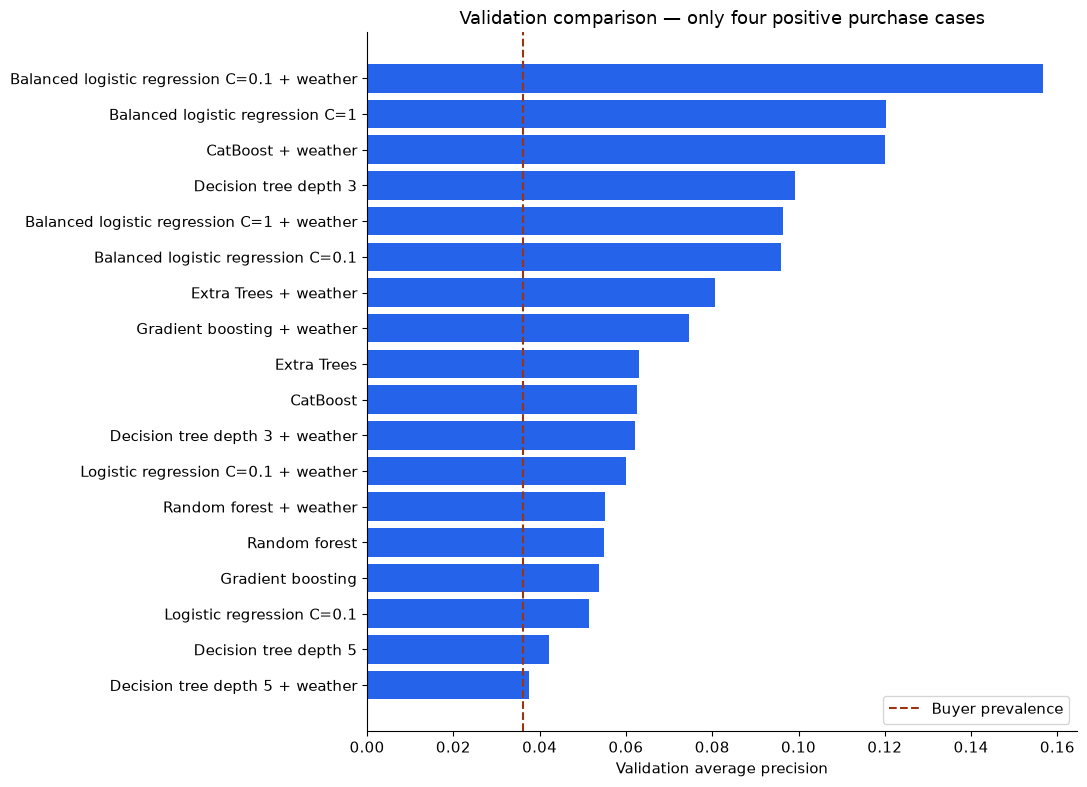

In [6]:
display(validation[["candidate","input_count","average_precision","precision","recall","f1","threshold"]]
        .sort_values("average_precision",ascending=False).round(3))
scores = validation.sort_values("average_precision")
scores["Display model"] = scores["candidate"].str.replace(" / core_and_weather"," + weather",regex=False).str.replace(" / core","",regex=False)
fig, ax = plt.subplots(figsize=(11,8))
ax.barh(scores["Display model"], scores["average_precision"], color="#2563eb")
ax.axvline(scope["samples"]["validation"]["positives"] / scope["samples"]["validation"]["rows"],color="#9a3412",linestyle="--",label="Buyer prevalence")
ax.set(xlabel="Validation average precision",title="Validation comparison — only four positive purchase cases")
ax.legend();fig.tight_layout();plt.show()


## Selected-model training code

The code below recreates the selected pipeline when the private labelled file is present. It does not repeat model selection, change the threshold, deploy the model or modify the frozen pest-return experiment. A shared copy without private rows can still display the saved aggregate results above and below.

In [7]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix
project = BASE.parent
private = project / "outputs/model_validation/20261030_programme_end_purchase/labelled_programmes_private.csv"
if private.exists():
    import sys
    if str(project) not in sys.path: sys.path.insert(0,str(project))
    from scripts.research_programme_end_purchase import partition
    rows = pd.read_csv(private,parse_dates=["anchor","outcome_end"],float_precision="round_trip")
    training, tuning, assessment, _ = partition(rows)
    features = result["raw_inputs"]
    categories = ["premise_type","pest_type","district"]
    numeric = [f for f in features if f not in categories]
    prepare = ColumnTransformer([
        ("numbers",make_pipeline(SimpleImputer(strategy="median",keep_empty_features=True),StandardScaler()),numeric),
        ("categories",OneHotEncoder(handle_unknown="ignore",min_frequency=10,sparse_output=False),categories)])
    model = make_pipeline(prepare,LogisticRegression(C=.1,class_weight="balanced",max_iter=2000,random_state=20261030))
    fit_rows = pd.concat([training,tuning],ignore_index=True)
    model.fit(fit_rows[features],fit_rows.label)
    probability = model.predict_proba(assessment[features])[:,1]
    prediction = probability >= result["threshold"]
    replay = confusion_matrix(assessment.label,prediction,labels=[0,1]).ravel().tolist()
    assert replay == [result["assessment"][key] for key in ["tn","fp","fn","tp"]]
    print("Selected model refitted on",len(fit_rows),"rows; saved assessment matrix reproduced.")
else:
    print("Private rows are not included here. Saved aggregate results remain available; refitting needs the private project data.")


Selected model refitted on 862 rows; saved assessment matrix reproduced.


## Test results

Accuracy alone is misleading because only 16 of 346 test examples have another purchase. The selected threshold is 0.99; this value was chosen on the very small validation sample, not on test performance.

Model,rows,positive_cases,accuracy,precision,recall,f1,tp,fp,fn,tn
Selected model,346,16,0.9538,0.5000,0.0625,0.1111,1,1,15,329
Always no additional purchase,346,16,0.9538,0.0000,0.0000,0.0000,0,0,16,330
Previous programme purchaser,346,16,0.8988,0.1481,0.2500,0.1860,4,23,12,307


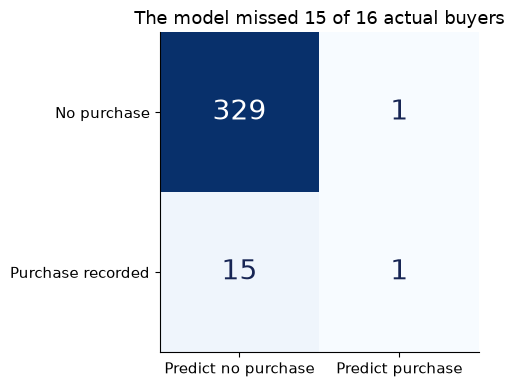

In [8]:
a=result["assessment"]
display(pd.DataFrame([{"Model": "Selected model",**a}]+[{"Model":name,**values} for name,values in result["baselines"].items()])
        [["Model","rows","positive_cases","accuracy","precision","recall","f1","tp","fp","fn","tn"]].round(4))
fig, ax = plt.subplots(figsize=(6,4))
matrix=[[a["tn"],a["fp"]],[a["fn"],a["tp"]]]
ax.imshow(matrix,cmap="Blues")
for i in range(2):
    for j in range(2): ax.text(j,i,str(matrix[i][j]),ha="center",va="center",fontsize=20,color="white" if matrix[i][j]>100 else "#172554")
ax.set(xticks=[0,1],xticklabels=["Predict no purchase","Predict purchase"],yticks=[0,1],yticklabels=["No purchase","Purchase recorded"],title="The model missed 15 of 16 actual buyers")
fig.tight_layout();plt.show()


## Which inputs helped?

This chart shuffles one input at a time in the validation data and measures the decrease in average precision. A larger positive value means the model depended on that input in this small sample. Negative values do not support keeping that input. These are not causal effects or reliable significance tests: the validation set contains only four buyers.

Input,validation_AP_drop_mean,validation_AP_drop_sd
Rain before visit: 14 days (mm),0.0690,0.0749
Rain before visit: 7 days (mm),0.0683,0.0249
Pest category,0.0504,0.0150
Residential or commercial,0.0244,0.0751
District,0.0152,0.0238
Earlier paid visits,0.0102,0.0198
Package sessions,0.0100,0.0197
Humidity before visit: 7 days (%),0.0046,0.0611
Programme sales (RM),0.0027,0.0596
Month pattern 2,0.0003,0.0005


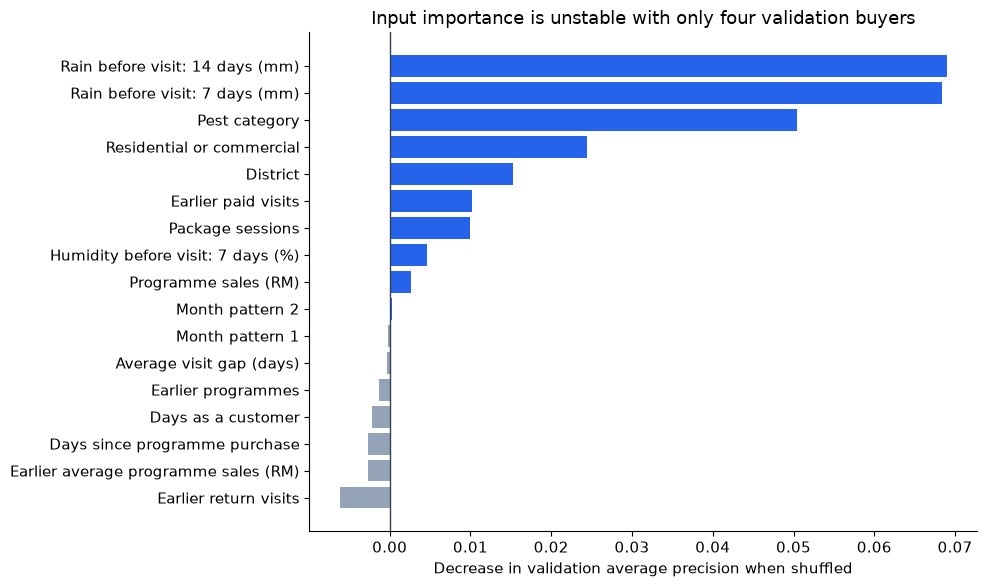

In [9]:
effects=pd.read_csv(E/"input_effects.csv")
effects["Input"]=effects["input"].map(lambda k:meaning[k][0])
display(effects[["Input","validation_AP_drop_mean","validation_AP_drop_sd"]].round(4))
fig,ax=plt.subplots(figsize=(10,6))
view=effects.sort_values("validation_AP_drop_mean")
ax.barh(view["Input"],view["validation_AP_drop_mean"],color=["#2563eb" if v>0 else "#94a3b8" for v in view.validation_AP_drop_mean])
ax.axvline(0,color="#334155",linewidth=1)
ax.set(xlabel="Decrease in validation average precision when shuffled",title="Input importance is unstable with only four validation buyers")
fig.tight_layout();plt.show()


## Conclusion

This is a genuinely trained new classifier, but it is not a strong replacement or an operationally validated renewal model. It found one buyer and missed fifteen. It failed the predeclared acceptance gate and was not deployed.

Do not replace the frozen pest-return model or call 95.38% accuracy an improvement. Further tests need a different defensible target or better outcome evidence, not a threshold chosen after seeing these test results.

The first pass treated unknown amounts as zero. That pass is retained under `superseded_missing_amount_handling`; the corrected run keeps them missing. Dates, algorithms and selection rules were not changed to select a favourable test score.

Source queries and job IDs are in `evidence/programme_end_purchase/source_receipt.json`. The full search implementation is `scripts/research_programme_end_purchase.py`. Notebook cells were executed sequentially in Python; a native Jupyter kernel is not installed.